# Assess completness of all MS comps from HLS across our time domain
2016-2023  
Anything missing?

In [1]:
# For some reason this is needed to get s3fs to work in ExtractUtils
# this upgrades to 0.3.4 even though we already specify this version in requirements_main...
#!pip install s3fs --upgrade

In [2]:
!pip install cogeo_mosaic

  Using cached cogeo_mosaic-7.0.1-py3-none-any.whl.metadata (17 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.2/65.2 kB 1.3 MB/s eta 0:00:00a 0:00:01
  Using cached supermorecado-0.1.2-py3-none-any.whl.metadata (8.2 kB)
  Using cached annotated_types-0.6.0-py3-none-any.whl.metadata (12 kB)
Using cached cogeo_mosaic-7.0.1-py3-none-any.whl (39 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 381.9/381.9 kB 5.0 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 25.1 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.8/261.8 kB 7.2 MB/s eta 0:00:00:00:01
Using cached supermorecado-0.1.2-py3-none-any.whl (14 kB)
Using cached annotated_types-0.6.0-py3-none-any.whl (12 kB)
  Attempting uninstall: pydantic
    Found existing installation: pydantic 1.10.8
    Uninstalling pydantic-1.10.8:
      Successfully uninstalled pydantic-1.10.8
  Attempting uninstall: morecan

In [3]:
import sys
import os

import geopandas as gpd
import pandas as pd
import matplotlib

sys.path.append('/projects/icesat2_boreal/lib')
sys.path.append('/projects/code/icesat2_boreal/lib')
import ExtractUtils
import maplib_folium

import folium
from folium import *

import datetime
import json
import glob

import s3fs

s3 = s3fs.S3FileSystem(anon=False)

import plotnine
from plotnine import *

matplotlib.rcParams['figure.figsize'] = [30, 10]

NASA MAAP


# Assess the HLS mosaics across a list of years
### Build mosaic json for mapping in folium - `5241 tiles` is the magic target set

In [4]:
# Spring 2022 c2020 composite - use this as template set of tiles (5241 tiles)
HLS_EXISTING_TINDEX_FN = '/projects/shared-buckets/nathanmthomas/DPS_tile_lists/HLS/c2020/HLS_stack_2023_v1/HLS_tindex_master.csv'

In [5]:
import importlib
import ExtractUtils
importlib.reload(ExtractUtils)

NASA MAAP


<module 'ExtractUtils' from '/projects/code/icesat2_boreal/lib/ExtractUtils.py'>

In [6]:
BAD_TILE_LIST = [3540,3634,3728,3823,3916,4004,41995,41807,41619]

In [7]:
OUTDIR = f'/projects/my-public-bucket/DPS_tile_lists/HLS/HLS_stack_2023_v1'

In [8]:
# These are the years of our study
YEARS_LIST = [2016,2017,2018,2019,2020,2021,2022,2023]

### Test MC comps metadata table generation

In [46]:
%%time
tindex_fn = '/projects/shared-buckets/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2020/HLS_tindex_master.csv'
df = ExtractUtils.write_mscomp_table(tindex_fn, RETURN_DF=True)

Get the list of HLS composite metadata jsons...
Map HLS composite metadata json reads across workers and concat to dataframe...
Wrote MS comp HLS params table: /projects/shared-buckets/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2020/HLS_input_params.csv
CPU times: user 36.7 s, sys: 370 ms, total: 37.1 s
Wall time: 5min 46s


In [47]:
df.head()

,tile_num,max_cloud,start_month_day,end_month_day,start_year,end_year,json_path,num_scenes,run_type
0,70,50,07-01,08-31,2016,2016,maap-ops-workspace/montesano/dps_output/do_HLS...,125,50_07-01_08-31_2016_2016
1,37073,50,07-01,08-31,2016,2016,maap-ops-workspace/montesano/dps_output/do_HLS...,146,50_07-01_08-31_2016_2016
2,28441,50,07-01,08-31,2016,2016,maap-ops-workspace/montesano/dps_output/do_HLS...,151,50_07-01_08-31_2016_2016
3,28704,50,07-01,08-31,2016,2016,maap-ops-workspace/montesano/dps_output/do_HLS...,131,50_07-01_08-31_2016_2016
4,37073,50,07-01,08-31,2016,2016,maap-ops-workspace/montesano/dps_output/do_HLS...,146,50_07-01_08-31_2016_2016


### Move DPS output into my private bucket

This test moves *contents* of `HLS_H30_2023_test` into `sibbork_input_test`:    
`aws s3 mv --recursive s3://maap-ops-workspace/montesano/tmp/HLS_H30_2023_test s3://maap-ops-workspace/montesano/tmp/sibbork_input_test/`  
 - the dir `HLS_H30_2023_test` disappears in the <to_dir> ... need to specify it explicitly
 - the dir `sibbork_input_test` is created automatically 
 
 
Do these:  
aws s3 mv --recursive s3://maap-ops-workspace/nathanmthomas/dps_output/do_HLS_stack_3-1-2_ubuntu/HLS_stack_2023_v1/HLS_H30_2020 s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2020 


aws s3 mv --recursive s3://maap-ops-workspace/nathanmthomas/dps_output/do_HLS_stack_3-1-2_ubuntu/HLS_stack_2023_v1/2023 s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2022/2023 

In [15]:
%%time 

HLS_mosaic_json_fn_LIST = []

#for YEAR in [2023]:
#for YEAR in YEARS_LIST:  
#for YEAR in [2018,2019,2020,'c2020',2022,2023]:  
#for YEAR in [2020,'c2020',2023]:
for YEAR in [2023]:

    USER = 'montesano'
    ALG_VERSION = 'HLS_stack_2023_v1'
    # In my bucket, this is ALWAYS used to identify output
    MS_COMP_NAME = f'HLS_H30_{YEAR}'
    DPS_IDENTIFIER = f'{ALG_VERSION}/{MS_COMP_NAME}'
    DPS_MONTH_LIST = '01 02 03 04 05 06 07 08 09 10 11 12'        
    
    DPS_DAY_MIN = 1
    OUTDIR = f'/projects/my-public-bucket/DPS_tile_lists/HLS/{DPS_IDENTIFIER}'
    !mkdir -p $OUTDIR
    
    # Build tindex
    args = f"--RETURN_DUPS --user {USER} --dps_identifier {DPS_IDENTIFIER} \
    -alg_name 'do_HLS_stack_3-1-2' -t 'HLS' -y 2023 --dps_month_list {DPS_MONTH_LIST} \
    -d_min {DPS_DAY_MIN} --outdir {OUTDIR}"
    
    !time python /projects/code/icesat2_boreal/lib/build_tindex_master.py $args

    # Use tindex
    if False:
        CURRENT_tindex_fn = f'{OUTDIR}/HLS_tindex_master.csv'

        HLS_mosaic_json_fn_local, CURRENT_tindex_matches_gdf = ExtractUtils.build_mosaic_json(
                                   CURRENT_tindex_fn, 
                                   boreal_tile_index_path = '/projects/shared-buckets/nathanmthomas/boreal_tiles_v003.gpkg', 
                                   BAD_TILE_LIST = BAD_TILE_LIST, 
                                   cols_list = ['tile_num','s3_path','local_path'])

        HLS_mosaic_json_fn = HLS_mosaic_json_fn_local.replace('/projects/my-public-bucket', 's3://maap-ops-workspace/shared/montesano')
        HLS_mosaic_json_fn_LIST.append(HLS_mosaic_json_fn)

INFO: Pandarallel will run on 30 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.
NASA MAAP

Building a list of tiles:
DPS ID:		HLS_stack_2023_v1/HLS_H30_2023
Type:		HLS
Year:		2023
Month:		['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
Days:		1-31

Output dir:  /projects/my-public-bucket/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2023
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/site-packages/botocore/session.py", line 1114, in get_component
    return self._components[name]
KeyError: 'user_agent_creator'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/projects/code/icesat2_boreal/lib/build_tindex_master.py", line 383, in <module>
    main()
  File "/projects/code/icesat2_boreal/lib/build_tindex_master.py", line 266, in main
    df = pd.concat([pd.DataFrame(s3.glob(os.path.join(bucket, searchkey)), columns=[c

### Test get file modification time for updating handling of duplicates

In [10]:
import os
import datetime

def modification_date(filename):
    t = os.path.getmtime(filename)
    return datetime.datetime.fromtimestamp(t)

In [11]:
#!pip install -U pandarallel

#### Test pandarallel to parallelize `apply`

In [69]:
from pandarallel import pandarallel

pandarallel.initialize(nb_workers=30, progress_bar=True)

INFO: Pandarallel will run on 30 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


In [70]:
%%time
df['creation time'] = df['local_path'].parallel_apply(modification_date) # can this be optimized?
df.sort_values(by=['creation time'], ascending=False, inplace=True ) # latest on top
df.head()

CPU times: user 2.54 s, sys: 2.13 s, total: 4.67 s
Wall time: 39.9 s


,Unnamed: 0,s3_path,local_path,file,tile_num,creation time
0,5248,s3://maap-ops-workspace/montesano/dps_output/d...,/projects/my-private-bucket/dps_output/do_HLS_...,HLS_2181_07-01_08-31_2022_2022.tif,2181,2023-10-19 22:17:07
1,5247,s3://maap-ops-workspace/montesano/dps_output/d...,/projects/my-private-bucket/dps_output/do_HLS_...,HLS_4011_07-01_08-31_2022_2022.tif,4011,2023-10-19 22:17:05
2,5246,s3://maap-ops-workspace/montesano/dps_output/d...,/projects/my-private-bucket/dps_output/do_HLS_...,HLS_1710_07-01_08-31_2022_2022.tif,1710,2023-10-19 22:17:03
3,5245,s3://maap-ops-workspace/montesano/dps_output/d...,/projects/my-private-bucket/dps_output/do_HLS_...,HLS_2995_07-01_08-31_2022_2022.tif,2995,2023-10-19 22:17:01
4,5244,s3://maap-ops-workspace/montesano/dps_output/d...,/projects/my-private-bucket/dps_output/do_HLS_...,HLS_3277_07-01_08-31_2022_2022.tif,3277,2023-10-19 22:16:57


#### Serial version of `apply` takes 11 min on ~5200 rows

In [213]:
# %%time
# df['creation time'] = df['local_path'].apply(modification_date) # can this be optimized?
# df.sort_values(by=['creation time'], ascending=False, inplace=True ) # latest on top
# df.head()

#### Remove duplicates subtile dirs

In [12]:
%%time
# delete dup tiles
dups_df = pd.read_csv('/projects/my-public-bucket/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2023/HLS_tindex_master_duplicates.csv')
DELETE_DIR_LIST = [os.path.dirname(x) for x in dups_df.s3_path.to_list()]

print(len( DELETE_DIR_LIST))  
DELETE_DIR_LIST[0]

14
CPU times: user 3.44 ms, sys: 2.54 ms, total: 5.98 ms
Wall time: 220 ms


's3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2023/mc10_07-01_08-31_2023_2023/2023/10/17/20/14/01/019936'

In [13]:
%%time

print(f'Deleting {len(DELETE_DIR_LIST)} dirs recursively ...')  
for d in DELETE_DIR_LIST:
    !aws s3 rm --quiet --recursive $d 

Deleting 14 dirs recursively ...
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
/bin/bash: line 1: aws: command not found
CPU times: user 18.9 ms, sys: 75.1 ms, total: 94 ms
Wall time: 2.68 s


#### Build tindex for c2020 only - from nathan's workspace

`TODO`: needs to be updated or deleted

Note:  
need to re-build tindex of c2020 HLS that was done from nathan's workspace  
b/c i think the HLS params csv is out of sync with the tindex, or something...  
*but* this needs to be done from his workspace.  

see here:  
/projects/shared-buckets/nathanmthomas/DPS_tile_lists/HLS/c2020/HLS_stack_2023_v1/HLS_input_params.csv

In [37]:
# if False:
#     # For c2020 
#     MAAP_VERSION_PATH = f'{MAAP_VERSION}'
    
#     DPS_MONTH_LIST = '04'
#     DPS_DAY_MIN = 1
#     OUTDIR = f'/projects/my-public-bucket/DPS_tile_lists/HLS/c2020/{MAAP_VERSION_PATH}'
#     !mkdir -p $OUTDIR
    
#     # Build tindex
#     args = f"--RETURN_DUPS --user 'nathanmthomas' --maap_version {MAAP_VERSION_PATH} -alg_name 'do_HLS_stack_3-1-2' -t 'HLS' -y 2023 --dps_month_list {DPS_MONTH_LIST} -d_min {DPS_DAY_MIN} --outdir {OUTDIR}"
#     !time python /projects/code/icesat2_boreal/lib/build_tindex_master.py $args

In [119]:
import importlib
import ExtractUtils
importlib.reload(ExtractUtils)

<module 'ExtractUtils' from '/projects/code/icesat2_boreal/lib/ExtractUtils.py'>

## Build lists for DPS follow-up &  Map completed tiles by run_name

In [14]:
boreal_tile_index = gpd.read_file('/projects/shared-buckets/nathanmthomas/boreal_tiles_v003.gpkg')

In [15]:
HLS_EXISTING_TINDEX_FN

'/projects/shared-buckets/nathanmthomas/DPS_tile_lists/HLS/c2020/HLS_stack_2023_v1/HLS_tindex_master.csv'

In [16]:
TILES_NEEDED = pd.read_csv(HLS_EXISTING_TINDEX_FN).tile_num.to_list()
len(TILES_NEEDED)

5241

In [17]:
import importlib
importlib.reload(ExtractUtils)

NASA MAAP


<module 'ExtractUtils' from '/projects/code/icesat2_boreal/lib/ExtractUtils.py'>

2023


/projects/code/icesat2_boreal/lib/ExtractUtils.py:505: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
/projects/code/icesat2_boreal/lib/ExtractUtils.py:505: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.


Axes(0.231094,0.11;0.562811x0.77) Axes(0.182189,0.11;0.562811x0.77)


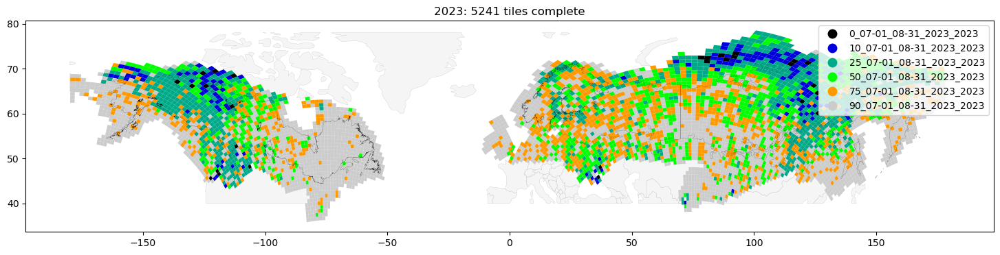

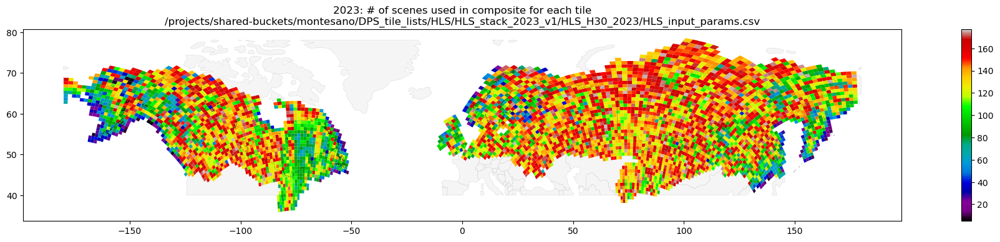

In [18]:
%matplotlib inline

dict_year_missing_tiles = dict()

#for YEAR in  ['c2015','c2020']+YEARS_LIST:
#for YEAR in [2018,2019,2020]:  
#for YEAR in [2018,2019,2020,'c2020',2022,2023]: 
for YEAR in [2023]:
    
    # Right now MS comps are spread across multiple users
    mscomp_params_table_fn_montesano = f'/projects/shared-buckets/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_{YEAR}/HLS_input_params.csv'
    mscomp_params_table_fn_nathanmthomas = f'/projects/shared-buckets/nathanmthomas/DPS_tile_lists/HLS/HLS_H30_{YEAR}/HLS_stack_2023_v1/HLS_input_params.csv'
    
    if YEAR == 'c2020':
        mscomp_params_table_fn = f'/projects/shared-buckets/nathanmthomas/DPS_tile_lists/HLS/{YEAR}/HLS_stack_2023_v1/HLS_input_params.csv'
    elif YEAR == 'c2015':
        mscomp_params_table_fn = f'/projects/shared-buckets/nathanmthomas/DPS_tile_lists/HLS/{YEAR}/HLS_stack_2022_v2/11/HLS_input_params.csv'
    elif os.path.exists(mscomp_params_table_fn_montesano):
        mscomp_params_table_fn = mscomp_params_table_fn_montesano
    elif os.path.exists(mscomp_params_table_fn_nathanmthomas):
        mscomp_params_table_fn = mscomp_params_table_fn_nathanmthomas
    else:
        mscomp_params_table_fn = None
        print(f'{YEAR} not started yet...')
        
    if mscomp_params_table_fn is not None:
        
        #
        # Build dataframe of HLS tiles DPS run types (input params) to show completed/missing for this year
        #
        print(YEAR)
        df_params = pd.read_csv(mscomp_params_table_fn)
        boreal_tindex_params = boreal_tile_index.merge(df_params[['tile_num','run_type','num_scenes']], how='left', left_on='tile_num', right_on='tile_num')
        boreal_tindex_params.groupby(['run_type']).size()

        CURRENT_MISSING_TILES = list(set(TILES_NEEDED) - set(boreal_tindex_params.tile_num.to_list()))
        n_tiles_missing = len(CURRENT_MISSING_TILES)
        
        #
        # Preserve the latest list of missing tiles for DPS
        #
        dict_year_missing_tiles[YEAR] = CURRENT_MISSING_TILES
        # write a list and read into DPS_mscomp_stack.ipynb to run through DPS
        nowtime = pd.Timestamp.now().strftime('%Y%m%d%H')
        tile_list_text_fn = f'/projects/my-public-bucket/DPS_tile_lists/tmp/tile_list_4_dps_followup_HLS_H30_{YEAR}_{nowtime}.txt'
        with open(tile_list_text_fn, 'w') as f:
            f.write(json.dumps(CURRENT_MISSING_TILES))
            
        # 
        # Make plots
        #
        MAP_MISSING = False
        if len(dict_year_missing_tiles[YEAR]) > 0:
            # Get a df of the missing tiles
            CURRENT_MISSING_tindex_gdf = boreal_tindex_params[boreal_tindex_params.tile_num.isin(dict_year_missing_tiles[YEAR])]
            ax_missing = ExtractUtils.plot_gdf_on_world(CURRENT_MISSING_tindex_gdf, MAP_COL='tile_group', DO_TYPE='False')
            ax_missing.set_title(f'{YEAR}: {n_tiles_missing} core tiles missing (might not be critical)')
            MAP_MISSING = True
            
        ax_types = ExtractUtils.plot_gdf_on_world(boreal_tindex_params)
        ax_types.set_title(f'{YEAR}: {boreal_tindex_params[~boreal_tindex_params.run_type.isnull()].shape[0]} tiles complete')
        
        ax_num_scenes = ExtractUtils.plot_gdf_on_world(boreal_tindex_params, MAP_COL="num_scenes")
        ax_num_scenes.set_title(f'{YEAR}: # of scenes used in composite for each tile\n{mscomp_params_table_fn}')
        if MAP_MISSING:
            print(ax_missing, ax_types, ax_num_scenes)
        else:
            print(ax_types, ax_num_scenes)
        

In [212]:
# 2023
# In north slope, mc75 and mc90 seems to create very noisy results.
REDO_TILES = [2588,3266,3083,3084,41056] # do with mc50
REDO_TILES += list(range(41053,41056+1))
REDO_TILES += list(range(3263,3264+1)) + list(range(3173,3176+1))

REDO_TILES = [3081] + [41246,41247,41248] + [3172,3173,3174,] + [3266,3083,3084,3176]
                   
print(REDO_TILES)    

[3081, 41246, 41247, 41248, 3172, 3173, 3174, 3266, 3083, 3084, 3176]


In [118]:
# Example of how to find missing 'need' tiles from a list of 'have'
need = [1,2,3,4,5,6,7,8]
have = [5,6,7,8,999]
missing_correct = list(set(need) - set(have))
missing_incorrect = list(set(have) - set(need))
missing_correct

[1, 2, 3, 4]

In [119]:
#CURRENT_COMPLETE_tindex_HLS_input_params[CURRENT_COMPLETE_tindex_HLS_input_params.tile_num == 2900].to_crs(4326).explore()

### Tile-level stats

<Axes: >

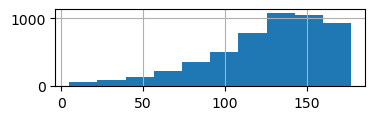

In [120]:
CURRENT_COMPLETE_tindex_HLS_input_params.num_scenes.hist(figsize=(4,1))

### Missing tiles for each year

In [121]:
files = glob.glob('/projects/my-public-bucket/DPS_tile_lists/tmp/*.txt')
for f in files:
    #Now read the file back into a Python list object
    with open(tile_list_text_fn, 'r') as f:
        tiles_list_ = json.loads(f.read())

# View in folium
https://docs.maap-project.org/en/latest/technical_tutorials/visualization/srtm-stac-mosaic.html

In [19]:
# Setup the mosaic tiling
tiler_base = "https://jqsd6bqdsf.execute-api.us-west-2.amazonaws.com/"
#tiler_base = "https://titiler.maap-project.org"
tiler_mosaic =  "".join([tiler_base, "mosaicjson/tiles/{z}/{x}/{y}"])

BAD_TILE_LIST = [3540,3634,3728,3823,3916,4004,41995,41807,41619]

In [20]:
boreal_tile_index = gpd.read_file('/projects/shared-buckets/nathanmthomas/boreal_tiles_v003.gpkg')

#### Set up HLS composite display details

In [21]:
MS_BANDNAME = 'NBR2'
MS_BANDMIN=0.25
MS_BANDMAX=0.45 
MS_BANDNUM=13 
MS_BANDCOLORBAR='nipy_spectral'

# Dict for specifying a different MS comp band to map
MS_BAND_DICT = {
    'name': MS_BANDNAME,
    'min' : MS_BANDMIN ,
    'max' : MS_BANDMAX , 
    'num' : MS_BANDNUM, 
    'cmap' : MS_BANDCOLORBAR,
    'legend_name': MS_BANDNAME + ' from HLS'
}

#### Paths to HLS mosaic json files

#### Build a list of HLS mosaic TileLayers to map

In [22]:
LIST_HLS_TILELAYER = []

for YEAR in ['c2015',2016,2017,2018,2019,2020,'c2020',2022,2023]:

    HLS_mosaic_json_fn = f's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_{YEAR}/HLS_tindex_master_mosaic.json'
    
    # Special cases - note the HLS alg version difs - noteable only because the time at which they were run is an indication of data availablity:
    #    full HLS L30 & S30 archive available through EarthData after back-processing finished in ~June 2023
    if YEAR == 'c2015': HLS_mosaic_json_fn =    f's3://maap-ops-workspace/shared/nathanmthomas/DPS_tile_lists/HLS/{YEAR}/HLS_stack_2022_v2/11/HLS_tindex_master_mosaic.json' 
    #if YEAR == 2020: HLS_mosaic_json_fn = f's3://maap-ops-workspace/shared/nathanmthomas/DPS_tile_lists/HLS/HLS_H30_{YEAR}/HLS_stack_2023_v1/HLS_tindex_master_mosaic.json'
    if YEAR == 'c2020': HLS_mosaic_json_fn = f's3://maap-ops-workspace/shared/nathanmthomas/DPS_tile_lists/HLS/{YEAR}/HLS_stack_2023_v1/HLS_tindex_master_mosaic.json'
    #if YEAR == 2022: HLS_mosaic_json_fn =    f's3://maap-ops-workspace/shared/nathanmthomas/DPS_tile_lists/HLS/HLS_H30_{YEAR}/HLS_stack_2023_v1/HLS_tindex_master_mosaic.json'
    print(HLS_mosaic_json_fn)
    TILELAYER = TileLayer(
                tiles= f"{tiler_mosaic}?url={HLS_mosaic_json_fn}&rescale={MS_BANDMIN},{MS_BANDMAX}&bidx={MS_BANDNUM}&colormap_name={MS_BANDCOLORBAR}",
                opacity=1,
                name=f"{YEAR} HLS comp",
                attr="MAAP",
                overlay=True
            )
    LIST_HLS_TILELAYER.append(TILELAYER)

s3://maap-ops-workspace/shared/nathanmthomas/DPS_tile_lists/HLS/c2015/HLS_stack_2022_v2/11/HLS_tindex_master_mosaic.json
s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2016/HLS_tindex_master_mosaic.json
s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2017/HLS_tindex_master_mosaic.json
s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2018/HLS_tindex_master_mosaic.json
s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2019/HLS_tindex_master_mosaic.json
s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2020/HLS_tindex_master_mosaic.json
s3://maap-ops-workspace/shared/nathanmthomas/DPS_tile_lists/HLS/c2020/HLS_stack_2023_v1/HLS_tindex_master_mosaic.json
s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2022/HLS_tindex_master_mosaic.json
s3://maap-ops-workspace/shared/mont

### AGB maps

In [30]:
AGB_localfull_H30_mosaic_json_fn = 's3://maap-ops-workspace/shared/lduncanson/DPS_tile_lists/BOREAL_MAP/boreal_agb_2023_v3/AGB_H30_2020/local_training_full/AGB_tindex_master_mosaic.json'
AGB_localfull_L30_mosaic_json_fn = 's3://maap-ops-workspace/shared/lduncanson/DPS_tile_lists/BOREAL_MAP/boreal_agb_2023_v3/AGB_L30_2020/local_training_full/AGB_tindex_master_mosaic.json'

In [31]:
MAX_AGB = 125
CMAP_AGB = 'viridis'

if True:
    AGB_localfull_H30_tiles_layer = TileLayer(
                tiles= f"{tiler_mosaic}?url={AGB_localfull_H30_mosaic_json_fn}&rescale=0,{MAX_AGB}&bidx=1&colormap_name={CMAP_AGB}",
                opacity=1,
                name="AGB localfull H30",
                attr="MAAP",
                overlay=True
            )
    AGB_localfull_L30_tiles_layer = TileLayer(
                tiles= f"{tiler_mosaic}?url={AGB_localfull_L30_mosaic_json_fn}&rescale=0,{MAX_AGB}&bidx=1&colormap_name={CMAP_AGB}",
                opacity=1,
                name="AGB localfull L30",
                attr="MAAP",
                overlay=True
            )


    AGB_TILES_LAYER_DICT = {
        "layer": AGB_localfull_L30_tiles_layer,
        "cmap": CMAP_AGB,
        "max_val": MAX_AGB,
        "caption": AGB_localfull_L30_tiles_layer.layer_name
    }

In [23]:
importlib.reload(maplib_folium)

<module 'maplib_folium' from '/projects/code/icesat2_boreal/lib/maplib_folium.py'>

## Map each HLS mosaic

In [36]:
maplib_folium.MAP_DPS_RESULTS(tiler_mosaic, 
                                        boreal_tile_index[~boreal_tile_index.tile_num.isin(BAD_TILE_LIST)], 
                                        #boreal_tile_index[boreal_tile_index.tile_num.isin(dict_year_missing_tiles[2020])],
                              boreal_tile_index[~boreal_tile_index.tile_num.isin(BAD_TILE_LIST)],
                                        None,
                             mosaic_json_dict = 
                                  {     ######### PRODUCT LAYERS #######
                                        #---NASA ABoVE Aboveground Boreal Woody Biomass Density
                                        'agb_mosaic_json_s3_fn': AGB_localfull_H30_mosaic_json_fn,                                                        
                                        'topo_mosaic_json_s3_fn':     None,
                                        'mscomp_mosaic_json_s3_fn':   None, 
                                        'worldcover_json_s3_fn':      None,
                                        'tp_standage2020_json_s3_fn': None,
                                        'tp_tcc2020_json_s3_fn':      None,
                                        'tp_tcc2020slope_json_s3_fn': None,
                                        'tp_tcc2020pvalue_json_s3_fn':None 
                                     },
                                MS_BAND_DICT = MS_BAND_DICT,
                                # ADD_TILELAYER = {
                                #                 "layer": LIST_HLS_TILELAYER[0], 
                                #                 "cmap": MS_BANDCOLORBAR,
                                #                 "max_val": MS_BANDMAX,
                                #                 "caption": MS_BANDNAME + ' from ' + LIST_HLS_TILELAYER[0].layer_name
                                #             },
                                # HLS_TILELAYER_LIST = LIST_HLS_TILELAYER,
                                ADD_TILELAYER = AGB_TILES_LAYER_DICT
                             ) 